# Permission Risk Scoring — Garrett vs Borda vs Combined — Education & Reference


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

RANDOM_STATE = 42
FLAG_PCT = 0.15   # total fraction flagged, split evenly across both disagreement directions
CATEGORY = "Education & Reference"
RESULTS_DIR = "results_Education_and_Reference"
os.makedirs(RESULTS_DIR, exist_ok=True)
pd.set_option("display.max_rows", 20)

In [2]:
df = pd.read_csv("Android_Permission.csv")
df.shape

(29999, 184)

## 1. All Categories in the Dataset

In [3]:
df["Category"].value_counts()

Category
Entertainment        2827
Travel & Local       2154
Books & Reference    1959
Arcade & Action      1959
Brain & Puzzle       1873
                     ... 
Sports Games          341
Photography           297
Racing                288
Medical               270
Weather               173
Name: count, Length: 30, dtype: int64

## 2. Group into 6 Broad Categories

In [4]:
BROAD_CATEGORY_MAP = {
    "Arcade & Action": "Games", "Brain & Puzzle": "Games", "Casual": "Games",
    "Cards & Casino": "Games", "Sports Games": "Games", "Racing": "Games",
    "Social": "Social & Communication", "Communication": "Social & Communication",
    "News & Magazines": "Social & Communication",
    "Tools": "Productivity & Tools", "Business": "Productivity & Tools",
    "Finance": "Productivity & Tools", "Productivity": "Productivity & Tools",
    "Libraries & Demo": "Productivity & Tools",
    "Entertainment": "Entertainment & Media", "Media & Video": "Entertainment & Media",
    "Music & Audio": "Entertainment & Media", "Comics": "Entertainment & Media",
    "Photography": "Entertainment & Media",
    "Education": "Education & Reference", "Books & Reference": "Education & Reference",
    "Travel & Local": "Lifestyle & Health", "Personalization": "Lifestyle & Health",
    "Lifestyle": "Lifestyle & Health", "Health & Fitness": "Lifestyle & Health",
    "Sports": "Lifestyle & Health", "Transportation": "Lifestyle & Health",
    "Shopping": "Lifestyle & Health", "Medical": "Lifestyle & Health",
    "Weather": "Lifestyle & Health",
}
df["BroadCategory"] = df["Category"].map(BROAD_CATEGORY_MAP)
df["BroadCategory"].value_counts()

BroadCategory
Lifestyle & Health        8064
Games                     7020
Entertainment & Media     5044
Productivity & Tools      4625
Education & Reference     3264
Social & Communication    1982
Name: count, dtype: int64

## 3. Preprocessing — Remove Duplicates

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(27310, 185)

## 4. Map Real Permission Columns

In [6]:
PERMISSION_COLUMN_MAP = {
    "Camera": ["Hardware controls : take pictures and videos (D)"],
    "Location": ["Your location : coarse (network-based) location (D)","Your location : fine (GPS) location (D)","Default : coarse (network-based) location (S)"],
    "Contacts": ["Your personal information : read contact data (D)","Your personal information : write contact data (D)","Default : write contact data (S)","Your accounts : contacts data in Google accounts (D)"],
    "Microphone": ["Hardware controls : record audio (D)"],
    "Storage": ["Storage : modify/delete USB storage contents modify/delete SD card contents (D)","Default : modify/delete USB storage contents modify/delete SD card contents (S)"],
    "SMS": ["Services that cost you money : send SMS messages (D)","Your messages : edit SMS or MMS (D)","Your messages : read SMS or MMS (D)","Your messages : receive SMS (D)","Your messages : receive MMS (D)","Your messages : send SMS-received broadcast (S)"],
    "CallLogs": [],
    "Bluetooth": ["Network communication : create Bluetooth connections (D)","System tools : bluetooth administration (D)"],
    "Calendar": ["Your personal information : add or modify calendar events and send email to guests (D)","Your personal information : read calendar events (D)"],
    "PhoneState": ["Default : read phone state and identity (S)","Phone calls : read phone state and identity (D)"],
    "Internet": ["Default : full Internet access (S)","Network communication : full Internet access (D)"],
    "ReadPhoneNumbers": [],
}
PERMISSIONS = list(PERMISSION_COLUMN_MAP.keys())
perm_cols = {}
for target, sources in PERMISSION_COLUMN_MAP.items():
    valid = [c for c in sources if c in df.columns]
    perm_cols[target] = (df[valid].fillna(0).sum(axis=1) > 0).astype(int) if valid else pd.Series(0, index=df.index)
df = pd.concat([df, pd.DataFrame(perm_cols)], axis=1)
pd.Series({p: len(c) for p, c in PERMISSION_COLUMN_MAP.items()}, name="source_columns_used")

Camera              1
Location            3
Contacts            4
Microphone          1
Storage             2
SMS                 6
CallLogs            0
Bluetooth           2
Calendar            2
PhoneState          2
Internet            2
ReadPhoneNumbers    0
Name: source_columns_used, dtype: int64

## 5. Build Label and Proxy Risk Score

In [7]:
df["LabelEncoded"] = df["Class"].astype(int)
df["TrueLabel"] = df["LabelEncoded"].map({0: "Benign", 1: "Malicious"})
dpc = df["Dangerous permissions count"].astype(float).fillna(df["Dangerous permissions count"].median())
df["PrivacyRiskScore"] = (dpc - dpc.min()) / (dpc.max() - dpc.min() + 1e-9)
df[["TrueLabel", "PrivacyRiskScore"]].describe(include="all")

,TrueLabel,PrivacyRiskScore
count,27310,27310.000000
unique,2,NaN
top,Malicious,NaN
freq,18232,NaN
mean,NaN,0.100516
std,NaN,0.098926
min,NaN,0.000000
25%,NaN,0.033333
50%,NaN,0.066667
75%,NaN,0.133333


## 6. Select Category: Education & Reference

In [8]:
cat_df = df[df["BroadCategory"] == CATEGORY].reset_index(drop=True)
print(f"{CATEGORY}: {len(cat_df)} apps")
EXTRA_FEATURES = ["Rating", "Number of ratings", "Price", "Dangerous permissions count", "Safe permissions count"]
for c in EXTRA_FEATURES:
    cat_df[c] = pd.to_numeric(cat_df[c], errors="coerce").fillna(0)
FEATURE_COLS = PERMISSIONS + EXTRA_FEATURES
cat_df["TrueLabel"].value_counts(normalize=True)

Education & Reference: 3099 apps


TrueLabel
Malicious    0.669894
Benign       0.330106
Name: proportion, dtype: float64

## 7. Permission Rankings (shared base for Borda & Garrett)

In [9]:
N = len(PERMISSIONS)

def compute_rankings(data, permissions, label_col="LabelEncoded"):
    freq = data[permissions].sum()
    risk = pd.Series({p: data.loc[data[p] == 1, "PrivacyRiskScore"].mean() for p in permissions}).fillna(0)
    mal = pd.Series({p: data.loc[data[p] == 1, label_col].mean() for p in permissions}).fillna(0)
    return pd.DataFrame({
        "Permission": permissions,
        "FrequencyRank": freq.rank(ascending=False, method="min").astype(int).values,
        "PrivacyRank": risk.rank(ascending=False, method="min").astype(int).reindex(permissions).values,
        "MaliciousRank": mal.rank(ascending=False, method="min").astype(int).reindex(permissions).values,
    })

ranking_df = compute_rankings(cat_df, PERMISSIONS)
ranking_df

,Permission,FrequencyRank,PrivacyRank,MaliciousRank
0,Camera,6,5,1
1,Location,4,7,9
2,Contacts,7,2,8
3,Microphone,5,6,5
4,Storage,2,9,2
5,SMS,8,4,6
6,CallLogs,11,11,11
7,Bluetooth,10,3,10
8,Calendar,9,1,3
9,PhoneState,3,8,4


## 8. Borda Weights

In [10]:
def apply_borda(ranking_df, n):
    r = ranking_df.copy()
    r["BordaScore"] = (n - r["FrequencyRank"]) + (n - r["PrivacyRank"]) + (n - r["MaliciousRank"])
    return r

borda_df = apply_borda(ranking_df, N)
borda_w = borda_df.set_index("Permission")["BordaScore"]
borda_w = (borda_w / borda_w.sum()).sort_values(ascending=False)
borda_w

Permission
Camera              0.119403
Storage             0.114428
Calendar            0.114428
PhoneState          0.104478
Microphone          0.099502
Contacts            0.094527
Internet            0.089552
SMS                 0.089552
Location            0.079602
Bluetooth           0.064677
CallLogs            0.014925
ReadPhoneNumbers    0.014925
Name: BordaScore, dtype: float64

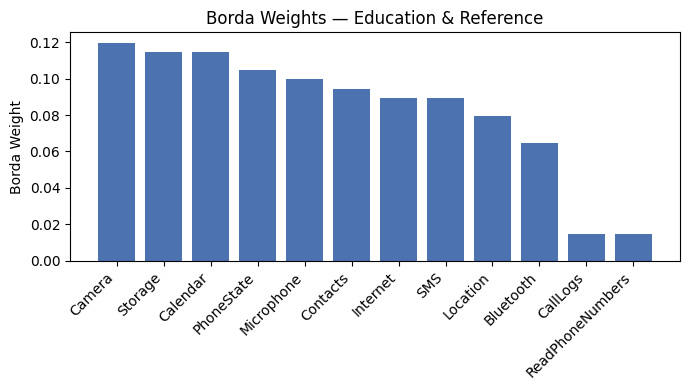

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(borda_w.index, borda_w.values, color="#4C72B0")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Borda Weight")
plt.title("Borda Weights — Education & Reference")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "borda_weights.png"), dpi=120)
plt.show()

## 9. Garrett Weights

In [12]:
GARRETT_PCT = np.array([2,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95,98])
GARRETT_SCORE = np.array([82,75,70,66,63,60,57,54,51,48,45,42,39,36,33,30,27,24,20,15,10])

def garrett_score(rank, n):
    return np.interp(100 * (rank - 0.5) / n, GARRETT_PCT, GARRETT_SCORE)

def apply_garrett(ranking_df, n):
    r = ranking_df.copy()
    r["GarrettTotal"] = (
        r["FrequencyRank"].apply(lambda x: garrett_score(x, n))
        + r["PrivacyRank"].apply(lambda x: garrett_score(x, n))
        + r["MaliciousRank"].apply(lambda x: garrett_score(x, n))
    )
    return r

garrett_df = apply_garrett(ranking_df, N)
garrett_w = garrett_df.set_index("Permission")["GarrettTotal"]
garrett_w = (garrett_w / garrett_w.sum()).sort_values(ascending=False)
garrett_w

Permission
Camera              0.107445
Calendar            0.104409
Storage             0.102318
PhoneState          0.095638
Microphone          0.092602
Contacts            0.089869
Internet            0.089228
SMS                 0.086530
Location            0.080457
Bluetooth           0.071349
CallLogs            0.040077
ReadPhoneNumbers    0.040077
Name: GarrettTotal, dtype: float64

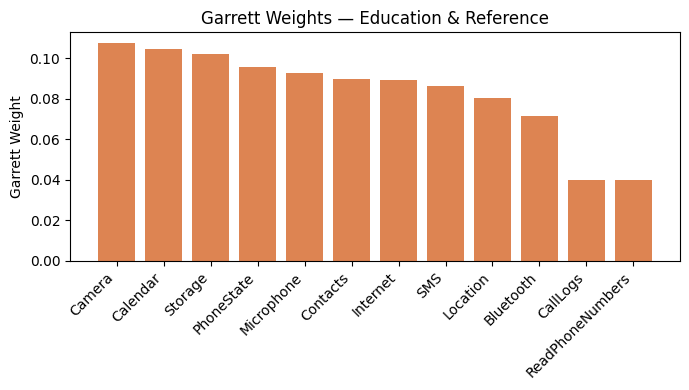

In [13]:
plt.figure(figsize=(7, 4))
plt.bar(garrett_w.index, garrett_w.values, color="#DD8452")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Garrett Weight")
plt.title("Garrett Weights — Education & Reference")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "garrett_weights.png"), dpi=120)
plt.show()

## 10. Combined Weights (average of Borda and Garrett)

In [14]:
combined_w = ((borda_w.reindex(PERMISSIONS) + garrett_w.reindex(PERMISSIONS)) / 2)
combined_w = (combined_w / combined_w.sum()).sort_values(ascending=False)
combined_w

Permission
Camera              0.113424
Calendar            0.109418
Storage             0.108373
PhoneState          0.100058
Microphone          0.096052
Contacts            0.092198
Internet            0.089390
SMS                 0.088041
Location            0.080030
Bluetooth           0.068013
CallLogs            0.027501
ReadPhoneNumbers    0.027501
dtype: float64

## 11. Shared Pipeline Functions

In [15]:
def score_apps(data, weights):
    perm_score = sum(data[p] * weights[p] for p in PERMISSIONS)
    return 0.9 * perm_score + 0.1 * data["PrivacyRiskScore"]

def flag_balanced(data, scores, pct=FLAG_PCT):
    n_each = int(len(data) * pct / 2)
    benign_mask = data["LabelEncoded"] == 0
    mal_mask = data["LabelEncoded"] == 1
    benign_idx = scores[benign_mask].sort_values(ascending=False).head(n_each).index
    mal_idx = scores[mal_mask].sort_values(ascending=True).head(n_each).index
    flagged = pd.Series(False, index=data.index)
    flagged.loc[benign_idx] = True
    flagged.loc[mal_idx] = True
    return flagged

def evaluate(y_true, scores, threshold=0.5):
    preds = (scores >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores) if pd.Series(y_true).nunique() > 1 else float("nan"),
    }

def run_classifiers(X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled):
    results = {}
    dt = DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE)
    dt.fit(X_train, y_train)
    results["Decision Tree"] = evaluate(y_test, dt.predict_proba(X_test)[:, 1])

    rf = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=RANDOM_STATE)
    rf.fit(X_train, y_train)
    results["Random Forest"] = evaluate(y_test, rf.predict_proba(X_test)[:, 1])

    ada = AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE)
    ada.fit(X_train, y_train)
    results["AdaBoost"] = evaluate(y_test, ada.predict_proba(X_test)[:, 1])

    svm = SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE)
    svm.fit(X_train_scaled, y_train)
    results["SVM"] = evaluate(y_test, svm.predict_proba(X_test_scaled)[:, 1])

    return results, {"dt": dt, "rf": rf, "ada": ada, "svm": svm}

def run_pipeline(weight_name, weights):
    scores = score_apps(cat_df, weights)
    flagged = flag_balanced(cat_df, scores)
    corrected = cat_df["LabelEncoded"].copy()
    corrected[flagged] = 1 - corrected[flagged]

    X = cat_df[FEATURE_COLS].values
    y = corrected.values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    clf_results, clf_models = run_classifiers(X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled)

    flagged_table = cat_df.loc[flagged, ["App", "Package", "TrueLabel"]].copy()
    flagged_table["Score"] = scores[flagged].round(4)
    flagged_table = flagged_table.sort_values("Score", ascending=False)

    return {
        "weight_name": weight_name,
        "scores": scores,
        "flagged_mask": flagged,
        "flagged_table": flagged_table,
        "n_flipped": int(flagged.sum()),
        "clf_results": clf_results,
        "clf_models": clf_models,
        "X_test": X_test, "y_test": y_test, "X_test_scaled": X_test_scaled,
    }

# Section A — Garrett-Only Pipeline

In [16]:
result_garrett = run_pipeline("Garrett", garrett_w)
print(f"Labels flipped: {result_garrett['n_flipped']} ({result_garrett['n_flipped']/len(cat_df)*100:.1f}%)")
result_garrett["flagged_table"].head(15)

Labels flipped: 464 (15.0%)


,App,Package,TrueLabel,Score
1398,??????,net.daum.android.daum,Benign,0.7330
125,iCheater,com.appmakr.app198820,Benign,0.7097
2932,IU Mobile,iu.android,Benign,0.7063
17,GCF Excel 2010 Tutorial,org.gcflearnfree.excel2010,Benign,0.7063
2709,Kumpulan Do'a Harian,com.jatis.doa,Benign,0.7063
2745,Lucado Life Lessons,com.phonegap.lifelessons,Benign,0.7063
887,GCF Word 2010 Tutorial,org.gcflearnfree.word2010,Benign,0.7063
1613,AQ (Siri for Android),AQ.xml,Benign,0.6791
2825,?????????,com.nhn.android.search,Benign,0.6318
2664,m.Clemson,com.blackboard.android.central.clemson,Benign,0.5424


In [17]:
pd.DataFrame(result_garrett["clf_results"]).round(4)

,Decision Tree,Random Forest,AdaBoost,SVM
Accuracy,0.8081,0.8097,0.7919,0.7661
Precision,0.9568,0.9541,0.8357,0.9299
Recall,0.7470,0.7518,0.8578,0.7036
F1,0.8390,0.8410,0.8466,0.8011
ROC-AUC,0.8770,0.8995,0.8746,0.8602


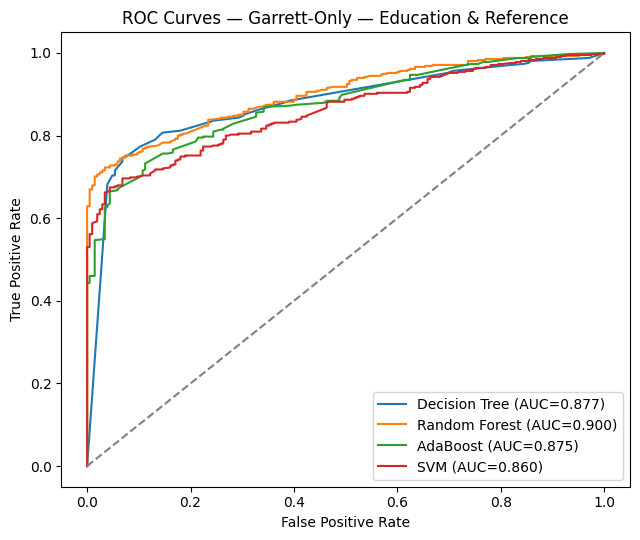

In [18]:
plt.figure(figsize=(6.5, 5.5))
for name in ["dt", "rf", "ada", "svm"]:
    label = {"dt": "Decision Tree", "rf": "Random Forest", "ada": "AdaBoost", "svm": "SVM"}[name]
    model = result_garrett["clf_models"][name]
    Xte = result_garrett["X_test_scaled"] if name == "svm" else result_garrett["X_test"]
    proba = model.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(result_garrett["y_test"], proba)
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(result_garrett['y_test'], proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Garrett-Only — Education & Reference")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "roc_garrett.png"), dpi=120)
plt.show()

# Section B — Borda-Only Pipeline

In [19]:
result_borda = run_pipeline("Borda", borda_w)
print(f"Labels flipped: {result_borda['n_flipped']} ({result_borda['n_flipped']/len(cat_df)*100:.1f}%)")
result_borda["flagged_table"].head(15)

Labels flipped: 464 (15.0%)


,App,Package,TrueLabel,Score
1398,??????,net.daum.android.daum,Benign,0.7753
125,iCheater,com.appmakr.app198820,Benign,0.7519
2932,IU Mobile,iu.android,Benign,0.7486
2745,Lucado Life Lessons,com.phonegap.lifelessons,Benign,0.7486
887,GCF Word 2010 Tutorial,org.gcflearnfree.word2010,Benign,0.7486
2709,Kumpulan Do'a Harian,com.jatis.doa,Benign,0.7486
17,GCF Excel 2010 Tutorial,org.gcflearnfree.excel2010,Benign,0.7486
1613,AQ (Siri for Android),AQ.xml,Benign,0.7027
2825,?????????,com.nhn.android.search,Benign,0.6713
2664,m.Clemson,com.blackboard.android.central.clemson,Benign,0.5740


In [20]:
pd.DataFrame(result_borda["clf_results"]).round(4)

,Decision Tree,Random Forest,AdaBoost,SVM
Accuracy,0.8371,0.8355,0.8129,0.7984
Precision,0.9511,0.9484,0.8485,0.9265
Recall,0.7976,0.7976,0.8771,0.7590
F1,0.8676,0.8665,0.8626,0.8344
ROC-AUC,0.9030,0.9106,0.9035,0.8814


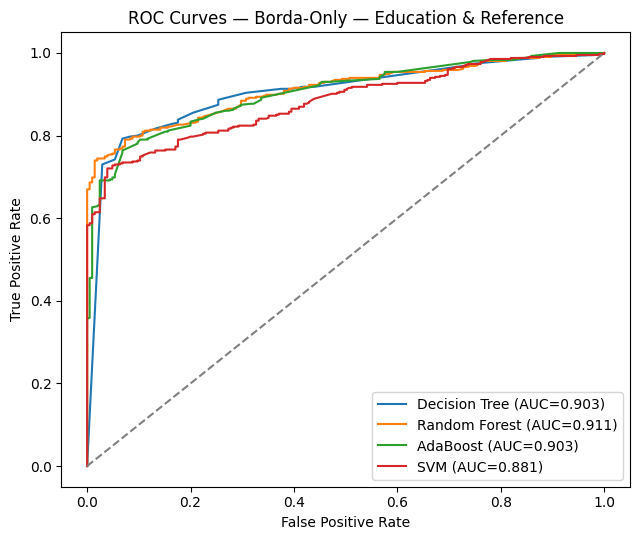

In [21]:
plt.figure(figsize=(6.5, 5.5))
for name in ["dt", "rf", "ada", "svm"]:
    label = {"dt": "Decision Tree", "rf": "Random Forest", "ada": "AdaBoost", "svm": "SVM"}[name]
    model = result_borda["clf_models"][name]
    Xte = result_borda["X_test_scaled"] if name == "svm" else result_borda["X_test"]
    proba = model.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(result_borda["y_test"], proba)
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(result_borda['y_test'], proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Borda-Only — Education & Reference")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "roc_borda.png"), dpi=120)
plt.show()

# Section C — Combined (Borda+Garrett) Pipeline

In [22]:
result_combined = run_pipeline("Combined", combined_w)
print(f"Labels flipped: {result_combined['n_flipped']} ({result_combined['n_flipped']/len(cat_df)*100:.1f}%)")
result_combined["flagged_table"].head(15)

Labels flipped: 464 (15.0%)


,App,Package,TrueLabel,Score
1398,??????,net.daum.android.daum,Benign,0.7541
125,iCheater,com.appmakr.app198820,Benign,0.7308
2932,IU Mobile,iu.android,Benign,0.7275
2745,Lucado Life Lessons,com.phonegap.lifelessons,Benign,0.7275
887,GCF Word 2010 Tutorial,org.gcflearnfree.word2010,Benign,0.7275
2709,Kumpulan Do'a Harian,com.jatis.doa,Benign,0.7275
17,GCF Excel 2010 Tutorial,org.gcflearnfree.excel2010,Benign,0.7275
1613,AQ (Siri for Android),AQ.xml,Benign,0.6909
2825,?????????,com.nhn.android.search,Benign,0.6516
2664,m.Clemson,com.blackboard.android.central.clemson,Benign,0.5582


In [23]:
pd.DataFrame(result_combined["clf_results"]).round(4)

,Decision Tree,Random Forest,AdaBoost,SVM
Accuracy,0.8371,0.8355,0.8129,0.7984
Precision,0.9511,0.9484,0.8485,0.9265
Recall,0.7976,0.7976,0.8771,0.7590
F1,0.8676,0.8665,0.8626,0.8344
ROC-AUC,0.9030,0.9106,0.9035,0.8814


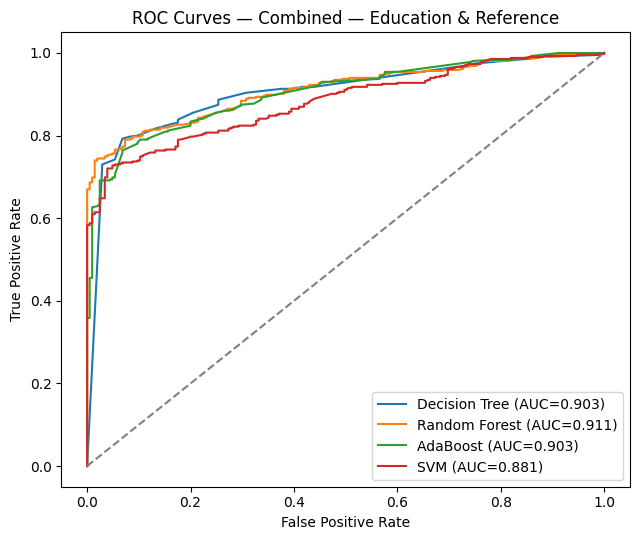

In [24]:
plt.figure(figsize=(6.5, 5.5))
for name in ["dt", "rf", "ada", "svm"]:
    label = {"dt": "Decision Tree", "rf": "Random Forest", "ada": "AdaBoost", "svm": "SVM"}[name]
    model = result_combined["clf_models"][name]
    Xte = result_combined["X_test_scaled"] if name == "svm" else result_combined["X_test"]
    proba = model.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(result_combined["y_test"], proba)
    plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(result_combined['y_test'], proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Combined — Education & Reference")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "roc_combined.png"), dpi=120)
plt.show()

# Final Comparison — All 3 Weighting Schemes x 4 Classifiers

In [25]:
rows = []
for res in [result_garrett, result_borda, result_combined]:
    for clf_name, metrics in res["clf_results"].items():
        row = {"WeightScheme": res["weight_name"], "Classifier": clf_name}
        row.update(metrics)
        rows.append(row)
full_comparison = pd.DataFrame(rows).round(4)
full_comparison

,WeightScheme,Classifier,Accuracy,Precision,Recall,F1,ROC-AUC
0,Garrett,Decision Tree,0.8081,0.9568,0.7470,0.8390,0.8770
1,Garrett,Random Forest,0.8097,0.9541,0.7518,0.8410,0.8995
2,Garrett,AdaBoost,0.7919,0.8357,0.8578,0.8466,0.8746
3,Garrett,SVM,0.7661,0.9299,0.7036,0.8011,0.8602
4,Borda,Decision Tree,0.8371,0.9511,0.7976,0.8676,0.9030
5,Borda,Random Forest,0.8355,0.9484,0.7976,0.8665,0.9106
6,Borda,AdaBoost,0.8129,0.8485,0.8771,0.8626,0.9035
7,Borda,SVM,0.7984,0.9265,0.7590,0.8344,0.8814
8,Combined,Decision Tree,0.8371,0.9511,0.7976,0.8676,0.9030
9,Combined,Random Forest,0.8355,0.9484,0.7976,0.8665,0.9106


In [26]:
full_comparison.to_csv(os.path.join(RESULTS_DIR, "full_comparison.csv"), index=False)
result_garrett["flagged_table"].to_csv(os.path.join(RESULTS_DIR, "flagged_garrett.csv"), index=False)
result_borda["flagged_table"].to_csv(os.path.join(RESULTS_DIR, "flagged_borda.csv"), index=False)
result_combined["flagged_table"].to_csv(os.path.join(RESULTS_DIR, "flagged_combined.csv"), index=False)
print(f"Saved all results to: {RESULTS_DIR}/")
print(os.listdir(RESULTS_DIR))

Saved all results to: results_Education_and_Reference/
['borda_weights.png', 'flagged_borda.csv', 'flagged_combined.csv', 'flagged_garrett.csv', 'full_comparison.csv', 'garrett_weights.png', 'roc_borda.png', 'roc_combined.png', 'roc_garrett.png']
